# Desafio 1 — Chegaram dados novos

**Cenário:** é janeiro de 2013 e o 2º semestre de 2012 chegou. O modelo novo deve substituir o `@champion`?

| Passo | Entrega |
|---|---|
| 1 | Dados v3 (`get_data --until 2012-12-31`, `dvc add`, tag `dados-v3`, `dvc push`) |
| 2 | Script de comparação `src/compare_models.py` (carregar, medir, decidir) |
| 3 | Estágio `compare`, o 6º do `dvc.yaml` (`cmd`, `deps`, `metrics`) |
| 4 | `dvc repro`: nova versão no Registry + `reports/comparacao.json` |
| 5 | `compare_models.py --promover`: tags `decisao`, `motivo` e `previous_champion` |
| 6 | Este notebook: comentários, impressões e dúvidas |

> Todas as células deste notebook **só leem** o estado do projeto (Git, DVC e MLflow): pode rodar *Run All* sem medo.
> Os comandos que alteram algo aparecem como texto, na ordem em que foram executados no terminal.
> Pré-requisito: servidor MLflow no ar (`bash scripts/start_mlflow.sh`).

In [1]:
import os, sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "params.yaml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

## 1. Dados v3

Mesma receita da T4:

```bash
python src/get_data.py --until 2012-12-31
dvc add data/raw/bike.csv
git add data/raw/bike.csv.dvc
git commit -m "Dados v3: 2012 completo"
git tag dados-v3
dvc push
```

In [2]:
%%bash
git tag -n1
echo
cat data/raw/bike.csv.dvc
wc -l data/raw/bike.csv

dados-v1        Dados v1: 2011
dados-v2        Dados v2: até jun/2012
dados-v3        Dados v3: 201

2 completo


outs:
- md5: 7747b2efcdd3801b83c1cfce2d600c15
  size: 1144308
  hash: md5
  path: bike.csv


17380 data/raw/bike.csv


## 2. Script de comparação: `src/compare_models.py`

Duas responsabilidades separadas de propósito:

| Modo | Quem roda | O que faz | Mexe no Registry? |
|---|---|---|---|
| sem argumentos | o estágio `compare` (`dvc repro`) | carrega `@champion` e o challenger (a versão de `models/run.json`), mede os dois **no mesmo teste**, decide pela regra do `params.yaml` e grava `reports/comparacao.json` | ❌ |
| `--promover` | uma pessoa, depois de revisar o `comparacao.json` | aplica a decisão gravada: tags `decisao` e `motivo`; se for promover, `previous_champion` + alias `@champion` | ✅ |

**Regra de decisão** (`params.yaml` → `compare.margem_minima`): o challenger só substitui o champion se o RMSE
cair **pelo menos 2%**. Diferenças menores podem ser ruído do período de teste.

**Proteção:** o `--promover` se recusa a aplicar a decisão se o `@champion` tiver mudado desde a comparação
(a decisão só vale contra o champion contra o qual foi tomada).

In [3]:
%%bash
python src/compare_models.py --help
echo
sed -n '/^compare:/,/^$/p' params.yaml

usage: compare_models.py [-h] [--promover]

Estágio `compare`: o modelo recém-treinado (challenger

) deve substituir o
@champion?

options:
  -h, --help  show this help message and exit
  --promover 

 aplica a decisão gravada em reports/comparacao.json


compare:
  # O challenger só substitui o @champion se o RMSE cair pelo menos 2%:
  # diferenças me

nores podem ser só ruído do período de teste.
  margem_minima: 0.02



## 3. Estágio `compare` (6º estágio do pipeline)

`always_changed: true` porque o `@champion` vive no Model Registry, fora do controle do DVC: sem isso, uma
promoção ou um rollback não faria o DVC perceber que a comparação ficou desatualizada.

In [4]:
%%bash
sed -n '/^  compare:/,$p' dvc.yaml
dvc dag

  compare:
    cmd: python src/compare_models.py
    deps:
    - src/compare_models.py
    - src/bik

e.py
    - models
    - data/split/test.csv
    params:
    - compare
    metrics:
    - reports/com

paracao.json:
        cache: false
    # O @champion vive no Model Registry, fora do controle do DVC

: sem isto, uma
    # promoção ou rollback não faria o DVC perceber que a comparação ficou velh

a.
    always_changed: true


               +-----------------------+                      
               | data/raw/bike.csv.dv

... (12 outputs left out)

                *     
    *        **        *        **********              *     
     **    ** 

          **    **          *******       *     
       *  *               *  *                   **

**   *     
  +----------+        +---------+                   +------+  
  | evaluate |        | c

ompare |                   | plot |  
  +----------+        +---------+                   +------+  

## 4. Retreino e comparação

```bash
dvc repro      # o dado mudou: o pipeline inteiro roda; train cria uma nova versão no Registry
git add dvc.lock metrics.json metrics_val.json reports/previsto_vs_real.png reports/comparacao.json
git commit -m "Pipeline retreinado com os dados v3 e comparação champion x challenger"
dvc push
```

In [5]:
%%bash
cat reports/comparacao.json
echo
dvc metrics show

{
  "teste": {
    "de": "2012-12-04",
    "ate": "2012-12-31",
    "linhas": 670
  },
  "margem_min

ima": 0.02,
  "challenger": {
    "versao": "9",
    "rmse": 62.78025790671387,
    "mae": 41.729808

22644132,
    "r2": 0.848304941715317
  },
  "champion": {
    "versao": "7",
    "rmse": 92.1917600

1086102,
    "mae": 64.13851732327079,
    "r2": 0.6728782248198821
  },
  "ganho_rmse": 0.319025280

57477375,
  "decisao": "promover",
  "motivo": "RMSE 62.8 (v9) x 92.2 (v7) no teste 2012-12-04 a 201

2-12-31: ganho de 31.9% >= margem de 2%"
}

... (11 outputs left out)

cao.json  41.72981          0.8483           62.78026           9                    64.13852       

 0.67288        92.19176         7                  promover   0.31903       -         0.02         

    RMSE 62.8 (v9) x 92.2 (v7) no teste 2012-12-04 a 2012-12-31: ganho de 31.9% >= margem de 2%  -  

      -         2012-12-31   2012-12-04  670


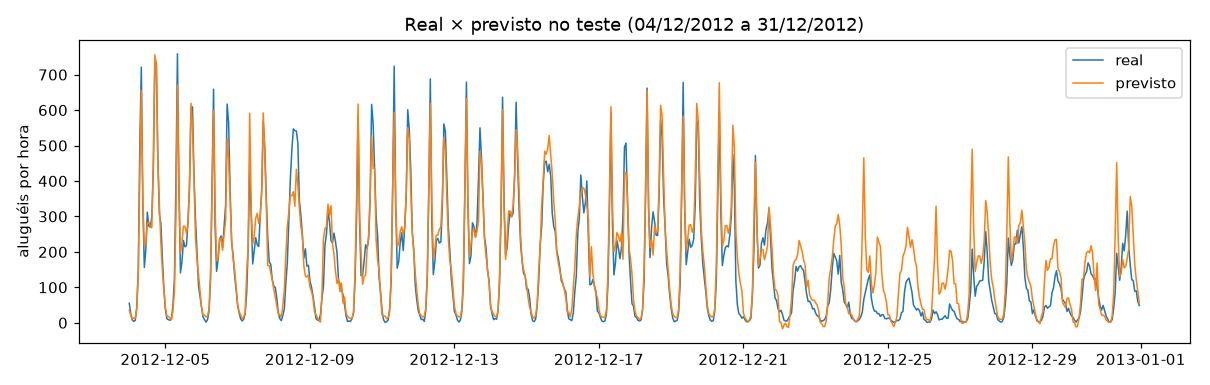

In [6]:
from IPython.display import Image
Image("reports/previsto_vs_real.png")

## 5. Decisão

```bash
python src/compare_models.py --promover    # ✅ Promovido: @champion agora é v9 (antes: v7)
python src/compare_models.py --promover    # ℹ️ v9 já é o @champion: nada a fazer  (idempotente)
```

Estado do Registry e linhagem da versão promovida:

In [7]:
import pandas as pd
from mlflow import MlflowClient
from bike import MODEL_NAME, tracking_uri

client = MlflowClient(tracking_uri())
aliases = client.get_registered_model(MODEL_NAME).aliases
print("aliases:", aliases)

linhas = []
for mv in client.search_model_versions(f"name='{MODEL_NAME}'"):
    linhas.append({"versão": int(mv.version),
                   "alias": ", ".join(a for a, v in aliases.items() if v == mv.version),
                   "status": mv.tags.get("validation_status", ""),
                   "decisao": mv.tags.get("decisao", ""),
                   "previous_champion": mv.tags.get("previous_champion", ""),
                   "descrição": mv.description})
display(pd.DataFrame(linhas).sort_values("versão").set_index("versão"))

champ = client.get_model_version_by_alias(MODEL_NAME, "champion")
print("motivo:", champ.tags["motivo"])
run = client.get_run(champ.run_id)
print("linhagem:", {k: run.data.tags[k] for k in ["data_version", "git_commit", "git_dirty", "train_rows", "train_until"]})

/home/vscode/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


aliases: {'champion': '9'}


,alias,status,decisao,previous_champion,descrição
versão,,,,,
1,,,,,Treino do pipeline (dvc repro)
2,,,,,Treino do pipeline (dvc repro)
3,,,,,Treino do pipeline (dvc repro)
4,,,,,Treino do pipeline (dvc repro)
5,,approved,,,Baseline da turma (T2): baseline-linear
6,,rolled_back,,5,Melhor run da turma na T2: rf-depth14
7,,approved,,5,Meu melhor run da T2: hgb-lr0.1-it300-leaves15
8,,,,,Treino do pipeline (dvc repro)
9,champion,approved,promover,7,Treino do pipeline (dvc repro)


motivo: RMSE 62.8 (v9) x 92.2 (v7) no teste 2012-12-04 a 2012-12-31: ganho de 31.9% >= margem de 2%


linhagem: {'data_version': '7747b2efcdd3801b83c1cfce2d600c15', 'git_commit': '6e1e699', 'git_dirty': 'false', 'train_rows': '16709', 'train_until': '2012-12-03'}


### Por que o antigo champion (v7) foi tão mal em dez/2012?

A v7 foi treinada só com 2011. Em 2012 a demanda cresceu, e um modelo de árvore **não extrapola**:
ele nunca prevê acima do que viu no treino. Resultado esperado: previsões sistematicamente **abaixo** do real.

In [8]:
import mlflow
from bike import regression_metrics, xy

test = pd.read_csv("data/split/test.csv")
X, y = xy(test)
mlflow.set_tracking_uri(tracking_uri())
resumo = {}
for v in ["7", champ.version]:
    pred = mlflow.pyfunc.load_model(f"models:/{MODEL_NAME}/{v}").predict(X)
    resumo[f"v{v}"] = {**regression_metrics(y, pred),
                       "média prevista": pred.mean(), "média real": y.mean(),
                       "viés (previsto - real)": (pred - y).mean()}
display(pd.DataFrame(resumo).T.round(2))

,rmse,mae,r2,média prevista,média real,viés (previsto - real)
v7,92.19,64.14,0.67,129.28,160.66,-31.38
v9,62.78,41.73,0.85,183.73,160.66,23.08


## 6. Comentários

- **Resultado:** a v9 (treinada com 2011 + 2012, dados v3) teve RMSE **62.8** contra **92.2** da v7 no mesmo teste
  (04 a 31/12/2012): ganho de **31.9%**, bem acima da margem de 2%. Decisão: **promover**. O `@champion` passou de v7 para v9.
- **Por que a v7 perdeu:** treinada só com 2011, ela não "conhece" o crescimento de 2012 e subestima a demanda
  (viés negativo na tabela acima). Modelos de árvore não extrapolam além do que viram.
- **A v9 também erra, mas para cima:** viés de +23 bicicletas/h. É o mesmo efeito visto na T1: dezembro tem
  Natal e Ano-Novo, e o modelo prevê esses dias como dias comuns. O erro da v9 é menor, mas não é zero.
- **Comparação justa:** os dois modelos foram medidos no **mesmo** teste, carregados do Registry. O RMSE gravado
  no run de origem da v7 (50.7, em dez/2011) **não** serve para comparar: era outro período.
- **Governança:** o estágio só **recomenda** (grava `decisao` e `motivo` no `comparacao.json`, versionado no Git);
  a promoção é um passo explícito e auditável (`--promover`), que deixa no Registry a decisão, o motivo e o
  `previous_champion` para um rollback.
- **Linhagem completa:** da versão 9 dá para chegar ao código (`git_commit`), ao dado exato (`data_version` = md5 do
  `bike.csv.dvc` da v3, tag `dados-v3`) e aos parâmetros (`dvc.lock`).
- **Limitações:**
  - a decisão olha só o RMSE de um mês (dezembro, com feriados); o ideal seria olhar também a validação temporal
    e mais de um período;
  - o estágio `compare` depende do estado do Registry (`always_changed`), então o `dvc status` sempre o mostra
    como desatualizado;
  - depois da promoção, rodar `dvc repro` de novo reescreve o `comparacao.json` com "o challenger já é o @champion".

## 7. Impressões e dúvidas

> ✍️ **Para preencher.** Algumas perguntas para guiar:
> - O que ficou mais claro com o desafio (DVC, MLflow, Registry)? O que ainda está confuso?
> - A margem de 2% faz sentido? Que outro critério você usaria (MAE, validação, vários períodos)?
> - Em produção, quem deveria rodar o `--promover`: uma pessoa ou o pipeline de CI/CD?
> - Alguma dificuldade com o ambiente (Codespace, MLflow, DVC)?

- *Impressões:* …
- *Dúvidas:* …